In [1]:
import os
import numpy as np
from scipy.special import jv
from scipy.sparse.linalg import eigsh, ArpackNoConvergence
from scipy.sparse import diags
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq
from joblib import Parallel, delayed
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# -----------------------------------------------------------------------------
# 0. Crear carpeta para archivos temporales (si no existe)
# -----------------------------------------------------------------------------
if not os.path.isdir("data/temp_G"):
    os.makedirs("data/temp_G")

In [3]:
# -----------------------------------------------------------------------------
# 1. Parámetros físicos (en nm y unidades compatibles)
# -----------------------------------------------------------------------------
# Conversión: 1 m = 1e9 nm.
d = 15 # Profundidad del NV en nm
D0 = 2e3 # 2e-9 * 1e18 # 2e-9 m²/us -> 2e9 nm²/s
D_s = 2e1 # nm^2/us
R = L = 100*d # 1e-6 m -> 1500 nm
delta = 2*d/3 # 1 nm (ancho de transición)
lambda_param = 0.75/d # en nm¹
n_modes_radial = 75 # Cantidad de modos de R()
m_max = 75 # Cantidad de modos de Z(z)
N_r = N_z = 90000 # Número de nodos en r y z
alpha_grid = 5.0 # Aglomeramiento de nodos cerca de z=0
z_c = lambda_param*L # altura crítica
# (Observación: 'varkappa' se fijará dentro del bucle

In [4]:
# -----------------------------------------------------------------------------
# 2. Malla adaptativa en z y perfil D(z) (NO depende de varkappa)
# -----------------------------------------------------------------------------
# 2.1 Construcción de la malla en z
j_vals = np.arange(N_z)
z = d + L * np.sinh(alpha_grid * j_vals / (N_z - 1)) / np.sinh(alpha_grid)
h = np.diff(z)  # h_j = z[j] - z[j-1]

# 2.2 Definición de D(z) (función)
def D(z_val):
    """
    Perfil de difusión completo con z en nm:
    D(z) = D_s + (D0 - D_s) * [ (1 - exp(-lambda_param*(z - d))) * (1 - S(z)) + S(z) ],
    con S(z) = 0.5 * [1 + tanh( (z - (z_c + d)) / delta ) ].
    """
    S = 0.5 * (1 + np.tanh((z_val - (z_c + d)) / delta))
    return D_s + (D0 - D_s) * ((1 - np.exp(-lambda_param * (z_val - d))) * (1 - S) + S)

In [5]:
# 2.3 Cálculo de D_values sobre toda la malla z
D_values = D(z)

# 2.4 Cálculo de D_eff (promedio armónico), que también se usa en tau = t * D_eff / d^2
integral_D = np.trapz(1.0 / D_values, z)
D_eff = L / integral_D

In [6]:
# -----------------------------------------------------------------------------
# 3. Definición de funciones compartidas:
#    - robin_eq(alpha): ecuación trascendental radial con parámetro varkappa
#    - R_func(alpha_array, rho_array): calcula los modos radiales J0(alpha_n * rho) normalizados
#    - build_system(n): ensambla y diagonaliza la parte axial para un modo radial n
# -----------------------------------------------------------------------------
def robin_eq(alpha, varkappa, D_eff):
    """
    Ecuación trascendental radial para hallar raíces alpha_n:
       alpha * J1(alpha*R) - (varkappa / D_eff) * J0(alpha*R) = 0.
    """
    return alpha * jv(1, alpha * R) - (varkappa / D_eff) * jv(0, alpha * R)

def find_alpha_roots(varkappa, D_eff, n_roots=n_modes_radial, step=1e-4):
    """
    Encuentra las primeras `n_roots` raíces alpha_n de robin_eq(alpha)=0
    en intervalos [0, ...] usando brentq y un paso `step`.
    """
    alpha_roots = []
    alpha_current = 0.0
    while len(alpha_roots) < n_roots:
        try:
            root = brentq(lambda a: robin_eq(a, varkappa, D_eff),
                          alpha_current, alpha_current + step, xtol=1e-6)
            alpha_roots.append(root)
            alpha_current = root + step
        except ValueError:
            alpha_current += step
    return np.array(alpha_roots)

def R_func(alpha_arr, rho_arr):
    """
    Calcula los modos radiales normalizados R_n(rho) = J0(alpha_n * rho)/sqrt(norm_n).
    Retorna:
      - R_normed: array con forma (n_modes_radial, len(rho_arr))
      - norms: vector con las normas (no se usa más adelante, pero lo dejamos para consistencia)
    """
    # alpha_arr: (n_modes_radial,)
    # rho_arr: (N_rhos,)
    alpha = alpha_arr.reshape(-1, 1)   # forma (n_modes_radial, 1)
    rho = rho_arr.reshape(1, -1)       # forma (1, N_rhos)
    R_matrix = jv(0, alpha * rho)      # (n_modes_radial, N_rhos)

    # Cálculo de normas analíticas: norms[n] = sqrt{ \int_0^R rho J0^2(alpha_n rho) d rho }
    J0R = jv(0, alpha_arr * R)  # (n_modes_radial,)
    J1R = jv(1, alpha_arr * R)  # (n_modes_radial,)
    norms = 0.5 * R ** 2 * (J0R**2 + J1R**2)  # (n_modes_radial,)
    norms = np.atleast_1d(norms)
    Nnorm = 1.0 / np.sqrt(norms)  # factor de normalización

    R_normed = Nnorm[:, None] * R_matrix  # (n_modes_radial, N_rhos)
    return R_normed, np.sqrt(norms)

def build_system(n, alpha_n, D_values, z, h, varkappa):
    """
    Ensambla la matriz tridiagonal A para el modo radial n y la diagonaliza
    para obtener m_max autovalores y autovectores.
    - n: índice del modo radial (0 .. n_modes_radial-1)
    - alpha_n: array con todas las raíces alpha (tamaño n_modes_radial)
    - D_values: perfil D(z) evaluado en todos los nodos z (longitud N_z)
    - z: malla en z (longitud N_z)
    - h: diferencias entre nodos de z (longitud N_z-1)
    - varkappa: valor actual de kappa en nm/s
    Retorna: (n, (evals, evecs)), donde
      - evals: vector de longitud m_max con los m_max autovalores más bajos
      - evecs: matriz (N_z, m_max) con los vectores propios normalizados
    """
    try:
        alpha = alpha_n[n]
        N = len(z)
        main_diag = np.zeros(N)
        upper_diag = np.zeros(N-1)
        lower_diag = np.zeros(N-1)

        # ---------------------------------------------------------------
        # 1. Índices internos (j=1 a N-2)
        # ---------------------------------------------------------------
        j_int = np.arange(1, N-1)  # j=1, 2, ..., N-2
        j_prev = j_int - 1         # j-1 = 0, 1, ..., N-3
        j_next = j_int + 1         # j+1 = 2, 3, ..., N-1
    
        # ---------------------------------------------------------------
        # 2. Cálculo de coeficientes (vectorizado)
        # ---------------------------------------------------------------
        # Promedios armónicos de D en interfases
        D_prev = 2*D_values[j_int]*D_values[j_prev]/(D_values[j_int] + D_values[j_prev])  # D_{j-1/2}
        D_next = 2*D_values[j_int]*D_values[j_next]/(D_values[j_int] + D_values[j_next])  # D_{j+1/2}
        
        # Espaciados promedio
        h_m  = h[j_prev]                 # h_{j-1/2}
        h_p  = h[j_int]                  # h_{j+1/2}
        h_j  = 0.5 * (h_m + h_p)         # h_j
    
        # Términos de la matriz (simétricos)
        main_diag[j_int] = (
              D_prev / (h_m * h_j)    # coeficiente de Z_{j-1}
            + D_next / (h_p * h_j)    # coeficiente de Z_{j+1}
            + alpha**2 * D_values[j_int]
        )
        lower_diag[j_prev] = - D_prev / (h_m * h_j)      # A[j, j-1]
        upper_diag[j_int]  = - D_next / (h_p * h_j)      # A[j, j+1]
    
        # ---------------------------------------------------------------
        # 3. Condiciones de contorno - Simétricas
        # ---------------------------------------------------------------
        # Superficie (z = d)
        h0 = h[0]
        h_1_2=z[1]-z[0]
        D0 = D_values[0]
        D_1_2 = 2*D0*D_values[1]/(D0 + D_values[1])
        
        main_diag[0] = D_1_2/h0/h_1_2 + varkappa/h0 + alpha ** 2 * D0
        upper_diag[0] = -D_1_2/h0/h_1_2
        lower_diag[0] = upper_diag[0]
        
        # Borde superior (z = L + d)
        hL = h[-1]
        h_3_2=z[-1]-z[-2]
        DL = D_values[-1]
        D_3_2 = 2 * D_values[-1] * D_values[-2] / (D_values[-1] + D_values[-2])
        
        main_diag[-1] = D_3_2 / hL/h_3_2 - varkappa / hL + alpha ** 2 * DL
        lower_diag[-2] = -D_3_2 / hL/h_3_2
        upper_diag[-1] = lower_diag[-2]

        # ---------------------------------------------------------------
        # 4. Ensamblar matriz tridiagonal simétrica
        # ---------------------------------------------------------------
        A = diags(
            diagonals=[main_diag, upper_diag, lower_diag],
            offsets=[0, 1, -1],
            shape=(N, N),
            format='csr'
        ) # + 1e-10 * identity(N)
        evals, evecs = eigsh(A, k=m_max, sigma=0.0, which='LM', tol=1e-6, maxiter=10000)
        if n==0 and varkappa==0:
            evals[0]=0.0
        else:
            pass
        return (n, (evals, evecs))

    except ArpackNoConvergence:
        print(f"Advertencia: El modo axial para n={n} no convergió. Se devuelven ceros.")
        return (n, (np.zeros(m_max), np.zeros((len(z), m_max))))

def T(t, lam):
    return np.exp(-np.abs(lam) * t)

def compute_P_vec(t, eigenvalues_ax, Z_tens, R0_mat, A_nm):
    """
    Computa P(ρ,z,t) más rápido usando matrices precalculadas.

    Parámetros:
    - t: escalar de tiempo
    - Z_tens: shape (Nz, n_modes_radial, m_max)
    - R0_mat: shape (n_modes_radial, N_r)
    - A_nm: coeficientes modales (n_modes_radial, m_max)

    Devuelve:
    - P: shape (Nz, Nr)
    """
    T_decay = T(t, eigenvalues_ax)  # (n_modes, m_max)
    W = A_nm * T_decay               # (n_modes, m_max)
    B = np.sum(Z_tens * W[None, :, :], axis=2)  # (Nz, n_modes)
    S = np.dot(R0_mat.T, B.T)  # (Nr, Nz)
    return np.maximum(S.T, 0)

In [7]:
# -----------------------------------------------------------------------------
# 4. Valores de varkappa a barrer (en nm/s)
# -----------------------------------------------------------------------------
varkappa_list = [0, 0.1, 1, 10, 100]

In [8]:
# -----------------------------------------------------------------------------
# 5. Malla temporal y pre-cálculo de J0(alpha_n * rho) y demás datos independientes
# -----------------------------------------------------------------------------
# 5.1 Nodos de integración en rho y z para G(t):
N_quad = 1000
rho_nodes = np.linspace(0.0, R, N_quad)  # np.linspace(0,R,N_quad)
z_nodes = np.linspace(d, L + d, N_quad)   # en [d, L+d]
rho0 = 0.0
z0 = d
dr = rho_nodes[1] - rho_nodes[0]
dz = z_nodes[1] - z_nodes[0]

# 5.2 Construcción de la red J0(alpha_n * rho) se hará DENTRO del bucle,
#     porque alpha_n depende de varkappa.

# 5.3 Construcción de Z_tens (modos axiales ante nodos z_nodes) se hará DENTRO del bucle,
#     ya que los autovectores axiales dependen de varkappa.

# 5.4 Matriz f_mat (factor dipolar) es independiente de varkappa:
R2 = rho_nodes**2
Z2 = (z_nodes + 1e-30)**2   # pequeño desplazamiento para evitar división por cero
f_mat = (3 * Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5  # forma (N_quad, N_quad)
f0_mat = (3*z0**2-rho0**2)/(rho0**2+z0**2)**2.5
rho_factor = (rho_nodes[:, None] * f0_mat * f_mat * dr * dz)

# 5.5 Vector de tiempos t en los que se evaluará G(t)
t_values = np.logspace(-3, 4, N_quad)   # forma (N_quad,)
tau_values = t_values * D_eff / d**2      # si se quiere comparar en unidades adimensionales

In [9]:
# -----------------------------------------------------------------------------
# 6. Bucle principal: para cada varkappa, calcular G(t) y guardarlo en un archivo temporal
# -----------------------------------------------------------------------------
for kapp in varkappa_list:
    print(f"--- Calculando G(t) para varkappa = {kapp} nm/s ---")

    # 6.1. Hallar raíces alpha_n (n_modes_radial valores)
    alpha_n = find_alpha_roots(kapp, D_eff, n_roots=n_modes_radial, step=1e-4)

    # 6.2. Modos radiales normalizados en nodos rho
    R0_mat, _ = R_func(alpha_n, rho_nodes)  # (n_modes_radial, N_quad)

    # 6.3. Resolver la parte axial en paralelo para cada modo radial n
    resultados_ax = Parallel(n_jobs=4, verbose=1)(
        delayed(build_system)(n, alpha_n, D_values, z, h, kapp)
        for n in range(n_modes_radial)
    )

    # Recolectar autovalores y autovectores
    eigenvalues_ax = np.zeros((n_modes_radial, m_max))      # (50, 50)
    eigenvectors_ax = np.zeros((n_modes_radial, m_max, len(z)))  # (50, 50, N_z)

    for (n_mode, (evals, evecs)) in resultados_ax:
        eigenvalues_ax[n_mode, :] = evals
        # evecs_T ya es (m_max, N_z)
        eigenvectors_ax[n_mode, :, :] = evecs.T

    # 6.4. Normalizar cada modo axial en z (∫ Z^2 dz = 1)
    norms_ax = np.sqrt(np.trapz(eigenvectors_ax**2, z, axis=2))  # (n_modes_radial, m_max)
    norms_ax[norms_ax == 0] = 1.0
    eigenvectors_ax /= norms_ax[:, :, None]

    # 6.5. Construir interpoladores cúbicos para Z_{n,m}(z) en z_nodes
    Z_interps = np.empty((n_modes_radial, m_max), dtype=object)
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z_interps[n, m] = CubicSpline(z, eigenvectors_ax[n, m, :], extrapolate=False)

    # 6.6. Condición inicial tipo delta en (rho0, z0):
    
    # 6.6.1 Evaluar R_n(rho0)
    R0_pt, _ = R_func(alpha_n, np.array([rho0]))  # (n_modes_radial, 1)
    R0_pt = R0_pt[:, 0]  # (n_modes_radial,)

    # 6.6.2 Evaluar Z_{n,m}(z0)
    Z0 = np.empty((n_modes_radial, m_max))
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z0[n, m] = Z_interps[n, m](z0)

    # 6.6.3 Coeficientes A_{n,m}
    A_nm = R0_pt[:, None] * Z0   # (n_modes_radial, m_max)

    # 6.8. Construcción de Z_tens[j, n, m] = Z_{n,m}(z_nodes[j])
    Z_tens = np.empty((N_quad, n_modes_radial, m_max))
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z_tens[:, n, m] = Z_interps[n, m](z_nodes)
    
    G_values = np.zeros_like(t_values)
    for i,t_val in enumerate(t_values):
        S=compute_P_vec(t_val,eigenvalues_ax,Z_tens, R0_mat, A_nm).T
        integrand = rho_factor * S  # (Nr, Nz) * (Nr, Nz)
        
        G_values[i] = (5/(16*np.pi)) * np.sum(integrand)

    # -----------------------------------------------------------------------------
    # 6.15. Guardar G_values en un archivo temporal y liberar memoria
    # -----------------------------------------------------------------------------
    temp_filename = os.path.join("data/temp_G", f"G_kappa_{kapp}.dat")
    # Preparamos un array de dos columnas: [t_values, G_values]
    data_to_save = np.column_stack([t_values, G_values])  # (N_quad, 2)
    header_str = "Tiempo(s)   G_k{}".format(kapp)

    np.savetxt(
        temp_filename,
        data_to_save,
        header=header_str,
        fmt="%.9e",
        comments=''
    )

    # Liberamos G_values inmediatamente
    del G_values
    del data_to_save

    print(f"  → Guardado temporal en '{temp_filename}' y liberado G_values.\n")

--- Calculando G(t) para varkappa = 0 nm/s ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  3.2min
[Parallel(n_jobs=4)]: Done  75 out of  75 | elapsed:  6.4min finished


  → Guardado temporal en 'data/temp_G\G_kappa_0.dat' y liberado G_values.

--- Calculando G(t) para varkappa = 0.1 nm/s ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  3.2min
[Parallel(n_jobs=4)]: Done  75 out of  75 | elapsed:  6.4min finished


  → Guardado temporal en 'data/temp_G\G_kappa_0.1.dat' y liberado G_values.

--- Calculando G(t) para varkappa = 1 nm/s ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  3.2min
[Parallel(n_jobs=4)]: Done  75 out of  75 | elapsed:  6.4min finished


  → Guardado temporal en 'data/temp_G\G_kappa_1.dat' y liberado G_values.

--- Calculando G(t) para varkappa = 10 nm/s ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  3.3min
[Parallel(n_jobs=4)]: Done  75 out of  75 | elapsed:  6.5min finished


  → Guardado temporal en 'data/temp_G\G_kappa_10.dat' y liberado G_values.

--- Calculando G(t) para varkappa = 100 nm/s ---


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  3.4min
[Parallel(n_jobs=4)]: Done  75 out of  75 | elapsed:  6.5min finished


  → Guardado temporal en 'data/temp_G\G_kappa_100.dat' y liberado G_values.



In [10]:
# --------------------------------------------------------
# 7. Al terminar el bucle, combinamos todos los archivos temporales
# --------------------------------------------------------
print("→ Combinando archivos temporales en 'VariateKappa_G_vs_t.dat' ...")

primero = True
lista_Gcols = []

for kapp in varkappa_list:
    temp_filename = os.path.join("data/temp_G", f"G_kappa_{kapp}.dat")
    # Ahora le decimos a loadtxt que omita la cabecera (1 línea)
    arr = np.loadtxt(temp_filename, skiprows=1)   # forma (N_quad, 2)

    if primero:
        t_col = arr[:, 0]   # extraemos el vector de tiempos
        primero = False
    G_col = arr[:, 1]       # extraemos la columna G(t) para este kappa
    lista_Gcols.append(G_col)

# Después seguimos exactamente igual:
G_stack = np.vstack(lista_Gcols).T               # (N_quad, 8)
output_data = np.column_stack([t_col, G_stack])  # (N_quad, 1 + 8)

header_cols = ['Tiempo(s)'] + [f'G_k{int(kp*10)}' for kp in varkappa_list]
header_str = '   '.join(header_cols)

np.savetxt(
    "data/VariateKappa_G_vs_t.dat",
    output_data,
    header=header_str,
    fmt="%.9e",
    comments=''
)

print("→ Archivo final 'VariateKappa_G_vs_t.dat' creado con columnas:")
print("   ", header_cols)

→ Combinando archivos temporales en 'VariateKappa_G_vs_t.dat' ...
→ Archivo final 'VariateKappa_G_vs_t.dat' creado con columnas:
    ['Tiempo(s)', 'G_k0', 'G_k1', 'G_k10', 'G_k100', 'G_k1000']


In [11]:
df = pd.read_csv("data/VariateKappa_G_vs_t.dat",delim_whitespace=True,comment='#')

C:\Users\allan\AppData\Local\Temp\ipykernel_9036\694625601.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv("data/VariateKappa_G_vs_t.dat",delim_whitespace=True,comment='#')


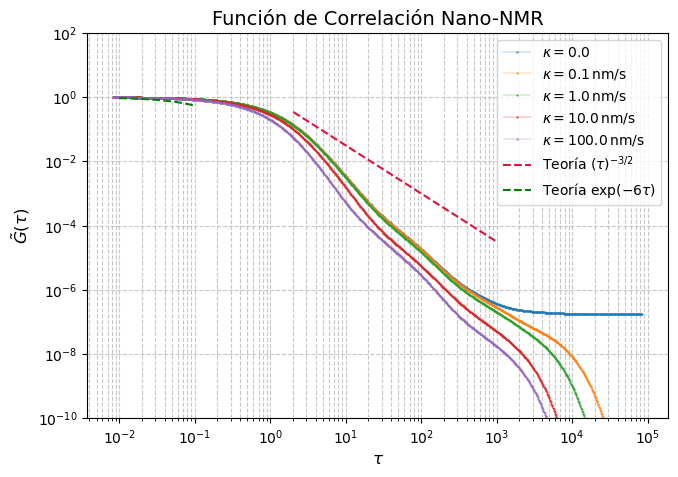

In [13]:
plt.figure(figsize=(7.5,5))
plt.loglog(tau_values, df.G_k0/df.G_k0[0], "o-", label=r"$\kappa=0.0$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_k1/df.G_k1[0], "o-", label=r"$\kappa=0.1\,\text{nm/s}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_k10/df.G_k10[0], "o-", label=r"$\kappa=1.0\,\text{nm/s}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_k100/df.G_k100[0], "o-", label=r"$\kappa=10.0\,\text{nm/s}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_k1000/df.G_k1000[0], "o-", label=r"$\kappa=100.0\,\text{nm/s}$", markersize=0.5, linewidth=0.25)
plt.plot(tau_values[(tau_values>=2)&(tau_values<=1000)], tau_values[(tau_values>=2)&(tau_values<=1000)]**-1.5, "--", label=r"Teoría $(\tau)^{-3/2}$", color="crimson", linewidth=1.5)
plt.plot(tau_values[(tau_values>=1e-2)&(tau_values<=0.1)], np.exp(-6*tau_values[(tau_values>=1e-2)&(tau_values<=0.1)]), "--", label=r"Teoría $\exp(-6\tau)$", color="green", linewidth=1.5)
# plt.xlabel("Tiempo (s)", fontsize=12)
plt.xlabel(r"$\tau$", fontsize=12)
plt.ylabel(r"$\tilde{G}(\tau)$", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.ylim((1e-10,1e2))
plt.grid(which="both", ls='--', alpha=0.7)
plt.savefig("figuras/correlacion_nanoNMR_kappaVariation.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()